# 03 | GBHeat — National and spatial demand analysis

**Analysis-only notebook.** This notebook reads **saved model outputs** generated using the assumptions in notebooks **01** (thermal) and **02** (COP and heating electricity). It **does not run** `run_heat_profiles_only()`, `run_cop_profiles()`, `run_electric_demand()` or recalculate LA redistribution.

**Outputs:** per-grid and GB half-hourly time series, annual energy and peak-demand summaries, technology breakdowns, optional **already-redistributed** Local Authority (LA) thermal profiles, tables and figures. All energy input profiles are assumed to contain **kWh per half-hour**, consistent with the GBHeat model. Electrical demand only covers the technologies processed by `electric_demand.py` (ASHP, GSHP and three hybrids); it is **not** total electricity demand or even necessarily all electric heating demand.

> **LA policy:** Use saved outputs from notebook 04 (`LA_HD_Profile` stock-informed redistribution). Do **not** recreate LA demand here using area shares. When LA profiles are absent, LA analysis is explicitly skipped. National and grid analysis remain available.


## 1. User settings — match notebook 01 and notebook 02

Select the same weather year, FES source year, pathway and future year. Set `ELECTRIC_PROFILES_REQUIRED=False` only if you intentionally want to inspect thermal outputs before running notebook 02.

In [1]:
weather_year = 2010
future_year = 2050
FES_year = "2022"
FES_scenario = "LW"

# Optional inspection: the same grid ID convention as notebook 01.
grid_id = "-3.5_56.0"

ELECTRIC_PROFILES_REQUIRED = True
LOAD_LA_PROFILES = True

# Notebook 04's current save_la_profiles may not include the weather year in its folder
# name. Set an explicit path if the candidate resolver cannot identify a unique folder.
# This can be an absolute path or a path relative to the repository root.
LA_PROFILE_FOLDER = None

SAVE_RESULTS = True
SHOW_PLOTS = True
FIGURE_DPI = 200


## 2. Imports and paths

Use `gbheatmodel.path.PROJECT_ROOT` just as notebook 01 does. No personal computer paths are embedded. Generated files are confined to `data/outputs/figures/<run_id>/03_National_Demand_Analysis/`.

In [2]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from gbheatmodel.path import PROJECT_ROOT

PROJECT_ROOT = Path(PROJECT_ROOT)
DATA_DIR = PROJECT_ROOT / "data"
OUTPUT_ROOT = DATA_DIR / "outputs"
RUN_ID = f"{weather_year}_{FES_year}_{FES_scenario}_{future_year}"
HEAT_DIR = OUTPUT_ROOT / "heating_profiles" / RUN_ID
ELECTRIC_DIR = OUTPUT_ROOT / "electric_demand" / RUN_ID
RESULT_DIR = OUTPUT_ROOT / "figures" / RUN_ID / "03_National_Demand_Analysis"
if SAVE_RESULTS:
    RESULT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Run: {RUN_ID}")
print(f"Thermal profiles: {HEAT_DIR}")
print(f"Electrical profiles: {ELECTRIC_DIR}")
print(f"Analysis outputs: {RESULT_DIR}")


Run: 2010_2022_LW_2050
Thermal profiles: C:\Users\s2583817\OneDrive - University of Edinburgh\Documents\Projects\PhD_Project\Python\GBHeatModel\data\outputs\heating_profiles\2010_2022_LW_2050
Electrical profiles: C:\Users\s2583817\OneDrive - University of Edinburgh\Documents\Projects\PhD_Project\Python\GBHeatModel\data\outputs\electric_demand\2010_2022_LW_2050
Analysis outputs: C:\Users\s2583817\OneDrive - University of Edinburgh\Documents\Projects\PhD_Project\Python\GBHeatModel\data\outputs\figures\2010_2022_LW_2050\03_National_Demand_Analysis


## 3. Read saved profiles and validate

Read *only* expected per-grid CSV files, rather than every CSV in a directory. Validate filenames, unique grid IDs, numeric/non-negative values, complete 30-minute indexing and grid-by-grid timestamp consistency. Do not silently drop problematic files or fill missing values with zero.

In [3]:
HEAT_PREFIX = "half_hourly_heat_profile_"
ELECTRIC_PREFIX = "elec_demand_"
ELECTRIC_COLUMNS = [
    "ASHP Elec", "GSHP Elec",
    "Hybrid (ASHP + BioLPG boiler) Elec",
    "Hybrid (ASHP + Hydrogen boiler) Elec",
    "Hybrid (ASHP + Electric resistive) Elec",
]


def parse_profile_file(path, kind):
    stem = path.stem
    if kind == "heat":
        if not stem.startswith(HEAT_PREFIX):
            raise ValueError(f"Unexpected thermal file: {path.name}")
        tail = stem[len(HEAT_PREFIX):]
        # The existing paper notebook extracts x_y from the start of the filename.
        match = re.match(r"^(-?\d+(?:\.\d+)?)_(-?\d+(?:\.\d+)?)(?:_|$)", tail)
        if not match:
            raise ValueError(f"Cannot determine grid ID from thermal filename: {path.name}")
        return match.group(1) + "_" + match.group(2)
    if kind == "electric":
        if not stem.startswith(ELECTRIC_PREFIX):
            raise ValueError(f"Unexpected electric file: {path.name}")
        suffix = f"_{FES_year}_{FES_scenario}_{future_year}"
        if not stem.endswith(suffix):
            raise ValueError(f"Electric file is not for this run: {path.name}")
        return stem[len(ELECTRIC_PREFIX):-len(suffix)]
    raise ValueError(kind)


def read_saved_profile(path):
    df = pd.read_csv(path, index_col=0)
    if df.empty or df.shape[1] == 0:
        raise ValueError(f"Empty profile: {path}")
    try:
        df.index = pd.to_datetime(df.index, errors="raise")
    except Exception as exc:
        raise ValueError(f"Cannot parse timestamps in {path}") from exc
    if df.index.has_duplicates or not df.index.is_monotonic_increasing:
        raise ValueError(f"Duplicate or unsorted timestamps in {path}")
    expected = pd.date_range(start=f"{future_year}-01-01", periods=len(df), freq="30min")
    if not df.index.equals(expected):
        raise ValueError(f"Non-contiguous half-hourly future-year timestamps in {path}")
    if len(df) not in (365 * 48, 366 * 48):
        raise ValueError(f"Unexpected number of half-hourly rows in {path}: {len(df)}")
    if len(df) != (366 if pd.Timestamp(f"{future_year}-12-31").is_leap_year else 365) * 48:
        raise ValueError(f"Number of rows does not match future year in {path}")
    if df.columns.duplicated().any():
        raise ValueError(f"Duplicate technology columns in {path}")
    for col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="raise")
    arr = df.to_numpy(dtype=float)
    if not np.isfinite(arr).all() or (arr < -1e-9).any():
        raise ValueError(f"NaN, infinite or negative values in {path}")
    return df


def read_grid_directory(folder, kind):
    folder = Path(folder)
    if not folder.is_dir():
        raise FileNotFoundError(f"Missing {kind} profile folder: {folder}")
    pattern = HEAT_PREFIX + "*.csv" if kind == "heat" else ELECTRIC_PREFIX + "*.csv"
    files = sorted(folder.glob(pattern))
    if not files:
        raise FileNotFoundError(f"No {kind} grid-profile files matching {pattern} in {folder}")
    result = {}
    ref_index = None
    ref_columns = None
    for file in files:
        gid = parse_profile_file(file, kind)
        if gid in result:
            raise ValueError(f"Duplicate grid ID {gid} in {folder}")
        frame = read_saved_profile(file)
        if ref_index is None:
            ref_index = frame.index
            ref_columns = set(frame.columns)
        if not frame.index.equals(ref_index):
            raise ValueError(f"Mismatched time index: {file.name}")
        if set(frame.columns) != ref_columns:
            raise ValueError(f"Mismatched technology columns: {file.name}")
        result[gid] = frame
    return result


heat_profiles = read_grid_directory(HEAT_DIR, "heat")
print(f"Loaded {len(heat_profiles)} thermal grid profiles.")

if ELECTRIC_DIR.exists():
    electric_profiles = read_grid_directory(ELECTRIC_DIR, "electric")
else:
    if ELECTRIC_PROFILES_REQUIRED:
        raise FileNotFoundError(f"Electric profiles not found: {ELECTRIC_DIR}. Run notebook 02 with save_model_outputs=True.")
    electric_profiles = {}
    print("No electricity outputs found; thermal-only analysis selected.")

if electric_profiles:
    if set(heat_profiles) != set(electric_profiles):
        raise ValueError("Heat/electric grid sets differ. Check the run settings and saved outputs.")
    for gid, frame in electric_profiles.items():
        if not frame.index.equals(heat_profiles[gid].index):
            raise ValueError(f"Thermal and electric timestamps differ in {gid}.")
        if set(frame.columns) != set(ELECTRIC_COLUMNS):
            raise ValueError(f"Unexpected electric columns in {gid}: {list(frame.columns)}")

if grid_id not in heat_profiles:
    print(f"Inspection grid {grid_id!r} not found; using {next(iter(heat_profiles))!r}.")
    grid_id = next(iter(heat_profiles))
print("Input verification passed.")


Loaded 738 thermal grid profiles.
Input verification passed.


## 4. Aggregate grid → national demand

This is an exact summation of saved grid profiles for each half-hour and technology, not a new model run. **Energy** uses kWh/half-hour. **Power** uses average MW = kWh × 2 / 1,000. Annual GWh = sum(kWh) / 1,000,000.

In [4]:
def national_by_technology(profile_dict):
    first = next(iter(profile_dict.values()))
    total = pd.DataFrame(0.0, index=first.index, columns=first.columns)
    for df in profile_dict.values():
        total = total.add(df.reindex(columns=total.columns), fill_value=0)
    return total


def grid_annual_peak_summary(profile_dict, demand_type):
    records = []
    for gid, df in profile_dict.items():
        step_kwh = df.sum(axis=1)
        records.append({
            "Grid_ID": gid,
            "Demand_Type": demand_type,
            "Annual_Energy_GWh": step_kwh.sum() / 1e6,
            "Local_Peak_MW": step_kwh.max() * 2 / 1000,
            "Local_Peak_Time": step_kwh.idxmax(),
        })
    return pd.DataFrame(records).sort_values("Annual_Energy_GWh", ascending=False)


national_heat_tech_kwh = national_by_technology(heat_profiles)
national_heat_kwh = national_heat_tech_kwh.sum(axis=1).rename("Thermal_Heat_kWh_per_half_hour")
heat_grid_summary = grid_annual_peak_summary(heat_profiles, "Thermal")

if electric_profiles:
    national_electric_tech_kwh = national_by_technology(electric_profiles)
    national_electric_kwh = national_electric_tech_kwh.sum(axis=1).rename("Modelled_Heating_Electricity_kWh_per_half_hour")
    electric_grid_summary = grid_annual_peak_summary(electric_profiles, "Modelled heating electricity")
else:
    national_electric_tech_kwh = None
    national_electric_kwh = None
    electric_grid_summary = None

national_halfhour = pd.DataFrame(index=national_heat_kwh.index)
national_halfhour[national_heat_kwh.name] = national_heat_kwh
national_halfhour["Thermal_Heat_GW"] = national_heat_kwh * 2 / 1e6
if national_electric_kwh is not None:
    national_halfhour[national_electric_kwh.name] = national_electric_kwh
    national_halfhour["Modelled_Heating_Electricity_GW"] = national_electric_kwh * 2 / 1e6

summary_rows = [{
    "Demand_Type": "Thermal",
    "Annual_Energy_TWh": national_heat_kwh.sum() / 1e9,
    "GB_Coincident_Peak_GW": national_heat_kwh.max() * 2 / 1e6,
    "GB_Coincident_Peak_Time": national_heat_kwh.idxmax(),
    "Sum_of_Local_Grid_Peaks_GW": heat_grid_summary["Local_Peak_MW"].sum() / 1000,
}]
if national_electric_kwh is not None:
    summary_rows.append({
        "Demand_Type": "Modelled heating electricity only",
        "Annual_Energy_TWh": national_electric_kwh.sum() / 1e9,
        "GB_Coincident_Peak_GW": national_electric_kwh.max() * 2 / 1e6,
        "GB_Coincident_Peak_Time": national_electric_kwh.idxmax(),
        "Sum_of_Local_Grid_Peaks_GW": electric_grid_summary["Local_Peak_MW"].sum() / 1000,
    })
national_summary = pd.DataFrame(summary_rows)

# Exact cross-checks against saved inputs; grid-specific annual and coincident totals.
np.testing.assert_allclose(
    heat_grid_summary["Annual_Energy_GWh"].sum(), national_heat_kwh.sum()/1e6,
    rtol=1e-10, atol=1e-6,
)
if national_electric_kwh is not None:
    np.testing.assert_allclose(
        electric_grid_summary["Annual_Energy_GWh"].sum(), national_electric_kwh.sum()/1e6,
        rtol=1e-10, atol=1e-6,
    )

display(national_summary)
display(heat_grid_summary.head(10))


,Demand_Type,Annual_Energy_TWh,GB_Coincident_Peak_GW,GB_Coincident_Peak_Time,Sum_of_Local_Grid_Peaks_GW
0,Thermal,222.766234,91.882624,2050-12-20 07:30:00,98.230221
1,Modelled heating electricity only,47.329064,22.109481,2050-12-20 07:30:00,24.516216


,Grid_ID,Demand_Type,Annual_Energy_GWh,Local_Peak_MW,Local_Peak_Time
3,-0.25_51.5,Thermal,12049.641401,5168.806265,2050-12-20 07:30:00
665,0.0_51.5,Thermal,11695.779956,5086.603127,2050-12-03 07:30:00
155,-2.0_52.5,Thermal,4611.676163,2051.675243,2050-12-19 07:30:00
188,-2.25_53.5,Thermal,4342.864928,2079.872476,2050-01-07 07:30:00
218,-2.5_53.5,Thermal,2801.565164,1353.160534,2050-01-07 07:30:00
18,-0.5_51.5,Thermal,2719.106920,1162.583891,2050-12-20 07:30:00
128,-1.75_52.5,Thermal,2644.382615,1184.741176,2050-12-20 07:30:00
283,-3.0_53.5,Thermal,2500.787860,1092.349646,2050-12-20 07:30:00
680,0.25_51.5,Thermal,2462.831771,1066.417158,2050-12-03 07:30:00
81,-1.25_53.0,Thermal,2341.349410,1105.840005,2050-12-06 07:30:00


## 5. Local Authority analysis (saved redistributions only)

Notebook 04 should export LA thermal profiles via `save_la_profiles()`. The current LA notebook saves its outputs under `data/outputs/LA_heat_profiles/`, and its folder naming may **omit the weather year**. Therefore an exact automatic match to the grid run cannot always be established. You may provide a specific `LA_PROFILE_FOLDER` and must verify that it was created for the same weather/FES/scenario/year/method. Without such a verified folder, this section skips LA processing.

**Important:** The LA analysis below reads only the saved thermal profiles. No LA electricity is estimated by allocating national or grid electrical demand. LA-to-GB agreement is a diagnostic; divergence is reported, not corrected.

In [5]:
LA_OUTPUT_BASE = OUTPUT_ROOT / "LA_heat_profiles"


def resolve_la_folder(explicit):
    if explicit is not None:
        path = Path(explicit)
        return path if path.is_absolute() else PROJECT_ROOT / path
    # Do not guess: legacy save_la_profiles names may omit weather year and method.
    return None


def read_la_directory(folder):
    files = sorted(Path(folder).glob("*.csv"))
    if not files:
        raise FileNotFoundError(f"No LA profile CSVs in {folder}")
    # Some saved profiles have an LAD21NM text column. Preserve labels separately.
    result = {}
    labels = {}
    reference_index = None
    reference_cols = None
    for file in files:
        raw = pd.read_csv(file, index_col=0)
        if "LAD21NM" in raw.columns:
            values = raw["LAD21NM"].dropna().unique().tolist()
            labels[file.stem] = str(values[0]) if values else file.stem
            raw = raw.drop(columns=["LAD21NM"])
        else:
            labels[file.stem] = file.stem
        if not len(raw) or not len(raw.columns):
            raise ValueError(f"Empty LA profile: {file}")
        raw.index = pd.to_datetime(raw.index, errors="raise")
        if raw.index.has_duplicates or not raw.index.is_monotonic_increasing:
            raise ValueError(f"Invalid LA timestamps in {file}")
        for col in raw.columns:
            raw[col] = pd.to_numeric(raw[col], errors="raise")
        if not np.isfinite(raw.to_numpy(dtype=float)).all():
            raise ValueError(f"Non-finite LA values in {file}")
        if reference_index is None:
            reference_index = raw.index
            reference_cols = set(raw.columns)
        if not raw.index.equals(reference_index) or set(raw.columns) != reference_cols:
            raise ValueError(f"Inconsistent LA profile: {file}")
        if file.stem in result:
            raise ValueError(f"Duplicate LA profile key: {file.stem}")
        result[file.stem] = raw
    return result, labels


la_profiles = {}
la_names = {}
la_summary = None
la_national_kwh = None
la_conservation = None
la_folder = resolve_la_folder(LA_PROFILE_FOLDER) if LOAD_LA_PROFILES else None
if LOAD_LA_PROFILES and la_folder is None:
    print("LA analysis skipped: set LA_PROFILE_FOLDER to the verified output folder of notebook 04.")
elif LOAD_LA_PROFILES:
    if not la_folder.is_dir():
        raise FileNotFoundError(f"LA_PROFILE_FOLDER does not exist: {la_folder}")
    la_profiles, la_names = read_la_directory(la_folder)
    reference = next(iter(la_profiles.values()))
    if not reference.index.equals(national_heat_kwh.index):
        raise ValueError("Saved LA time index differs from the selected GB grid run.")
    if set(reference.columns) != set(national_heat_tech_kwh.columns):
        raise ValueError("Saved LA technology columns differ from GB grid profiles.")
    la_national_tech_kwh = national_by_technology(la_profiles)
    la_national_kwh = la_national_tech_kwh.sum(axis=1)
    la_summary = grid_annual_peak_summary(la_profiles, "LA redistributed thermal")
    la_summary = la_summary.rename(columns={"Grid_ID": "LA_Profile_File"})
    la_summary.insert(1, "Local_Authority", la_summary["LA_Profile_File"].map(la_names))

    difference = national_heat_tech_kwh.sub(la_national_tech_kwh, fill_value=0)
    la_conservation = pd.DataFrame({
        "Technology": difference.columns,
        "GB_Grid_Energy_GWh": national_heat_tech_kwh.sum().values / 1e6,
        "LA_Redistributed_Energy_GWh": la_national_tech_kwh.reindex(columns=difference.columns).sum().values / 1e6,
        "Grid_Minus_LA_GWh": difference.sum().values / 1e6,
        "Maximum_Absolute_Halfhourly_Difference_kWh": difference.abs().max().values,
    })
    print(f"Loaded {len(la_profiles)} saved LA thermal profiles from {la_folder}")
    print("LA redistribution diagnostic: difference is reported, never replaced or rescaled.")
    display(la_conservation)
    display(la_summary.head(10))


LA analysis skipped: set LA_PROFILE_FOLDER to the verified output folder of notebook 04.


## 6. Figures — selected grid and GB demand

These figures are exploratory outputs from the saved data; publication-quality spatial maps are handled by notebook 05. Power axes are average GW/MW over each half-hour. The electrical curve represents only the heating electricity components in `electric_demand.py`.

Saved: C:\Users\s2583817\OneDrive - University of Edinburgh\Documents\Projects\PhD_Project\Python\GBHeatModel\data\outputs\figures\2010_2022_LW_2050\03_National_Demand_Analysis\01_GB_halfhourly_demand.png


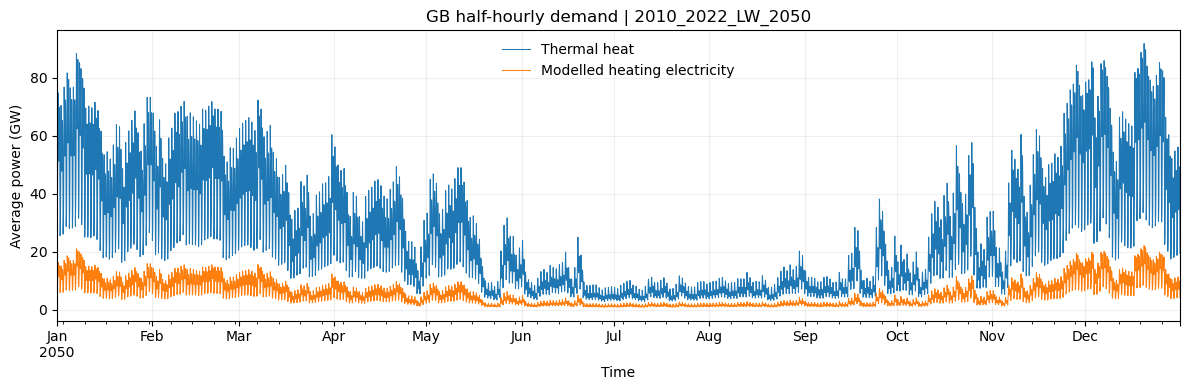

Saved: C:\Users\s2583817\OneDrive - University of Edinburgh\Documents\Projects\PhD_Project\Python\GBHeatModel\data\outputs\figures\2010_2022_LW_2050\03_National_Demand_Analysis\02_selected_grid_demand.png


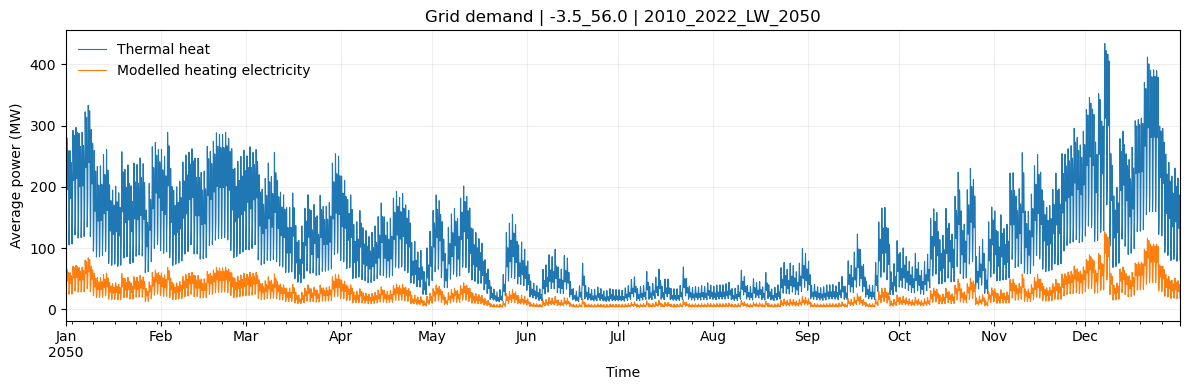

Saved: C:\Users\s2583817\OneDrive - University of Edinburgh\Documents\Projects\PhD_Project\Python\GBHeatModel\data\outputs\figures\2010_2022_LW_2050\03_National_Demand_Analysis\03_GB_heat_by_technology.png


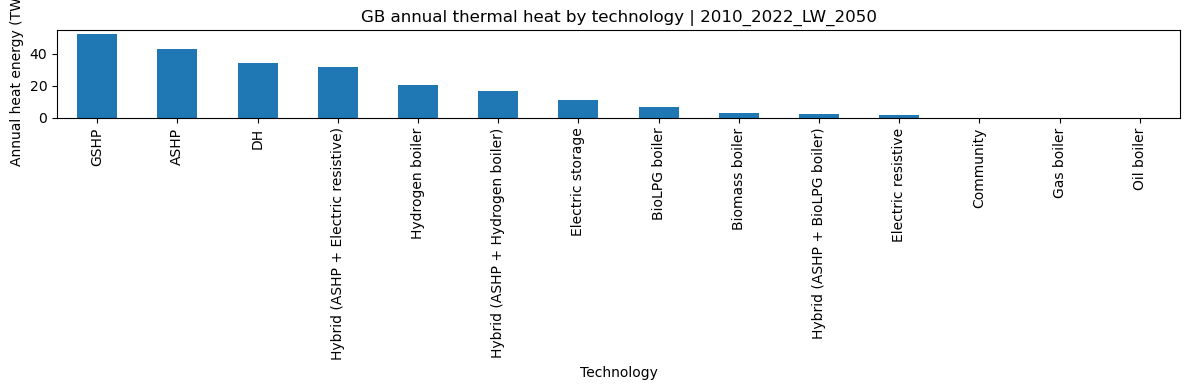

Saved: C:\Users\s2583817\OneDrive - University of Edinburgh\Documents\Projects\PhD_Project\Python\GBHeatModel\data\outputs\figures\2010_2022_LW_2050\03_National_Demand_Analysis\04_GB_heating_electricity_by_technology.png


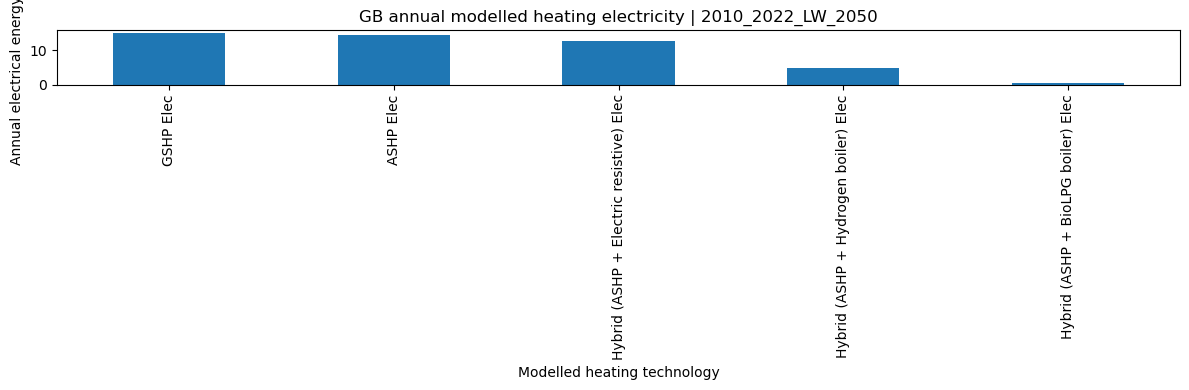

In [6]:
def render_figure(fig, filename):
    fig.tight_layout()
    if SAVE_RESULTS:
        target = RESULT_DIR / filename
        fig.savefig(target, dpi=FIGURE_DPI, bbox_inches="tight")
        print("Saved:", target)
    if SHOW_PLOTS:
        plt.show()
    else:
        plt.close(fig)


fig, ax = plt.subplots(figsize=(12, 4))
national_halfhour["Thermal_Heat_GW"].plot(ax=ax, lw=0.75, label="Thermal heat")
if "Modelled_Heating_Electricity_GW" in national_halfhour:
    national_halfhour["Modelled_Heating_Electricity_GW"].plot(
        ax=ax, lw=0.75, label="Modelled heating electricity"
    )
ax.set(title=f"GB half-hourly demand | {RUN_ID}", xlabel="Time", ylabel="Average power (GW)")
ax.legend(frameon=False)
ax.grid(alpha=0.2)
render_figure(fig, "01_GB_halfhourly_demand.png")

fig, ax = plt.subplots(figsize=(12, 4))
(heat_profiles[grid_id].sum(axis=1) * 2 / 1000).plot(ax=ax, label="Thermal heat", lw=0.8)
if electric_profiles:
    (electric_profiles[grid_id].sum(axis=1) * 2 / 1000).plot(ax=ax, label="Modelled heating electricity", lw=0.8)
ax.set(title=f"Grid demand | {grid_id} | {RUN_ID}", xlabel="Time", ylabel="Average power (MW)")
ax.legend(frameon=False)
ax.grid(alpha=0.2)
render_figure(fig, "02_selected_grid_demand.png")

fig, ax = plt.subplots(figsize=(12, 4))
(national_heat_tech_kwh.sum() / 1e9).sort_values(ascending=False).plot.bar(ax=ax)
ax.set(title=f"GB annual thermal heat by technology | {RUN_ID}", ylabel="Annual heat energy (TWh)", xlabel="Technology")
render_figure(fig, "03_GB_heat_by_technology.png")

if national_electric_tech_kwh is not None:
    fig, ax = plt.subplots(figsize=(12, 4))
    (national_electric_tech_kwh.sum() / 1e9).sort_values(ascending=False).plot.bar(ax=ax)
    ax.set(title=f"GB annual modelled heating electricity | {RUN_ID}", ylabel="Annual electrical energy (TWh)", xlabel="Modelled heating technology")
    render_figure(fig, "04_GB_heating_electricity_by_technology.png")

if la_summary is not None:
    fig, ax = plt.subplots(figsize=(11, 5))
    la_summary.head(20).iloc[::-1].plot.barh(
        x="Local_Authority", y="Annual_Energy_GWh", ax=ax, legend=False
    )
    ax.set(title=f"Top 20 LA thermal heat demand | {RUN_ID}", xlabel="Annual heat (GWh)", ylabel="Local Authority")
    render_figure(fig, "05_top_20_LA_thermal_demand.png")


## 7. Export analysis tables

Analysis exports are stored alongside the figures, separate from the main GBHeat simulation outputs. The `RUN_ID` includes all four core scenario assumptions. Do not commit generated outputs to Git unless intentionally distributing small examples.

In [7]:
if SAVE_RESULTS:
    national_halfhour.to_csv(RESULT_DIR / "GB_halfhourly_thermal_and_heating_electricity.csv", index_label="timestamp")
    national_summary.to_csv(RESULT_DIR / "GB_annual_and_coincident_peak_summary.csv", index=False)
    heat_grid_summary.to_csv(RESULT_DIR / "grid_thermal_annual_and_peak_summary.csv", index=False)
    (national_heat_tech_kwh.sum() / 1e6).rename("Annual_Heat_GWh").to_csv(
        RESULT_DIR / "GB_thermal_by_technology_GWh.csv"
    )
    if national_electric_tech_kwh is not None:
        electric_grid_summary.to_csv(RESULT_DIR / "grid_electric_annual_and_peak_summary.csv", index=False)
        (national_electric_tech_kwh.sum() / 1e6).rename("Annual_Heating_Electricity_GWh").to_csv(
            RESULT_DIR / "GB_heating_electricity_by_technology_GWh.csv"
        )
    if la_summary is not None:
        la_summary.to_csv(RESULT_DIR / "LA_thermal_annual_and_peak_summary.csv", index=False)
        la_conservation.to_csv(RESULT_DIR / "LA_redistribution_conservation_diagnostic.csv", index=False)
    print("Analysis outputs saved to:", RESULT_DIR)
else:
    print("SAVE_RESULTS=False; no figures or tables saved.")


Analysis outputs saved to: C:\Users\s2583817\OneDrive - University of Edinburgh\Documents\Projects\PhD_Project\Python\GBHeatModel\data\outputs\figures\2010_2022_LW_2050\03_National_Demand_Analysis


## Interpretation and limitations

- **Scientific source:** GBHeat's existing thermal model (`runner.py`) and electricity conversion (`cop.py`, `electric_demand.py`). Notebook 03 only aggregates *saved* outputs; it is not a substitute for notebooks 01/02.
- **Run consistency:** A matching folder name and timestamp grid do not by themselves prove that the saved files were produced using identical source-code versions or COP performance assumptions. Preserve provenance externally until the runner writes metadata files.
- **Power and energy:** Saved profiles represent kWh per 30-minute period; power is kWh × 2 / 1,000 (MW) or × 2 / 1,000,000 (GW). Thermal and electrical quantities are separate and should not be added.
- **Peaks:** The GB coincident peak is calculated from the summed GB half-hourly profile. The sum of local non-coincident peak magnitudes is reported separately; these are not equivalent.
- **LA:** Local Authority thermal results require the validated stock-informed output of notebook 04. A partial LA selection will not conserve GB totals, and this notebook does not reinterpret the difference as missing electricity or demand.
- **Electricity coverage:** Per `electric_demand.py`, only ASHP, GSHP and the three named hybrid columns are included; standalone resistance/storage heating and other sectors are outside the result.
- **Testing status:** The notebook is syntactically validated, but requires your local GBHeat outputs for a full execution test.
